In [3]:
import time
import pyautogui as pyg

print("3 秒後按下空白鍵")
time.sleep(3)

pyg.press("space")

print("測試完成")

3 秒後按下空白鍵
測試完成


In [4]:
import pyautogui as pyg

print("螢幕解析度：", pyg.size())

螢幕解析度： Size(width=1920, height=1080)


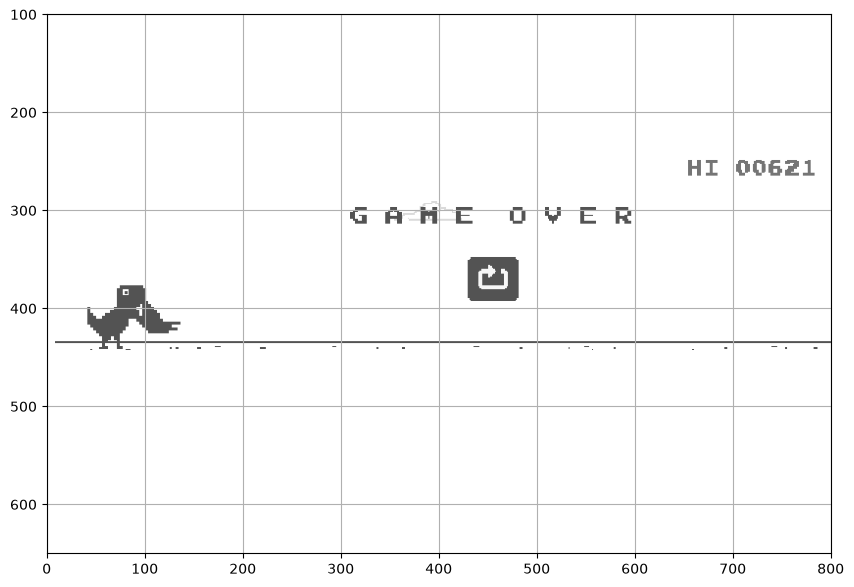

In [36]:

import mss
import numpy as np
import matplotlib.pyplot as plt

with mss.MSS() as sct:
    screen = np.array(sct.grab(sct.monitors[1]))

plt.figure(figsize=(12, 7))
plt.imshow(screen[:, :, [2, 1, 0]])
plt.xlim(0, 800)
plt.ylim(650, 100)
plt.grid()
plt.show()


In [35]:

import time
import cv2
import numpy as np
import pyautogui as pyg
import mss

pyg.PAUSE = 0.0
pyg.FAILSAFE = True

# ==============================
# 1. 仙人掌偵測設定
# ==============================

base_x = 180
base_width = 29

obstacle_area = {
    "left": base_x,
    "top": 400,
    "width": base_width,
    "height": 45
}

# ==============================
# 2. 鳥類偵測設定（新增）
# ==============================

# 根據目前 chrome://dino/ 截圖初步設定
BIRD_X = 180
BIRD_Y = 350
BIRD_WIDTH = 29
BIRD_HEIGHT = 25

bird_area = {
    "left": BIRD_X,
    "top": BIRD_Y,
    "width": BIRD_WIDTH,
    "height": BIRD_HEIGHT
}

# 鳥類通過後的低頭持續時間
DUCK_HOLD = 0.45

# ==============================
# 3. GAME OVER 偵測設定
# ==============================

game_over_area = {
    "left": 400,
    "top": 285,
    "width": 200,
    "height": 35
}

GAME_OVER_CHECK_INTERVAL = 10
GAME_OVER_CONFIRM_FRAMES = 3

game_over_count = 0

def detect_game_over(sct):

    img = np.array(sct.grab(game_over_area))

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_BGRA2GRAY
    )

    _, binary = cv2.threshold(
        gray,
        150,
        255,
        cv2.THRESH_BINARY_INV
    )

    dark_columns = np.count_nonzero(
        np.any(binary > 0, axis=0)
    )

    dark_pixels = np.count_nonzero(binary)

    return (
        dark_columns >= 65
        and dark_pixels >= 250
    )

# ==============================
# 4. 速度與跳躍設定
# ==============================

SPEED_FACTOR = 1.9
MAX_EXTEND_X = 130

CLEAR_FRAMES = 4
JUMP_HOLD = 0.11

last_obstacle = False
clear_count = 0

last_bird = False
bird_clear_count = 0
BIRD_CLEAR_FRAMES = 4

jump_count = 0
duck_count = 0

duck_until = 0
ducking = False

# ==============================
# 5. 障礙物偵測函式
# ==============================

def detect_obstacle(sct, area, min_h, max_h):

    img = np.array(sct.grab(area))

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_BGRA2GRAY
    )

    _, binary = cv2.threshold(
        gray,
        180,
        255,
        cv2.THRESH_BINARY_INV
    )

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        if 2 <= w <= 25 and min_h <= h <= max_h:
            return True

    return False

# ==============================
# 6. 開始執行
# ==============================

print("恐龍自動跳躍 + 鳥類低頭機器人啟動！")
print("立即開始偵測！")
print("仙人掌：跳躍")
print("鳥類：低頭")
print("GAME OVER：自動停止")

start_time = time.time()

try:
    with mss.MSS() as sct:

        frame_idx = 0

        while True:

            frame_idx += 1
            now = time.time()

            # --------------------------
            # GAME OVER 自動停止
            # --------------------------

            if frame_idx % GAME_OVER_CHECK_INTERVAL == 0:

                if detect_game_over(sct):
                    game_over_count += 1
                else:
                    game_over_count = 0

                if game_over_count >= GAME_OVER_CONFIRM_FRAMES:
                    print("\n偵測到 GAME OVER！")
                    break

            # --------------------------
            # 動態速度補償
            # --------------------------

            elapsed = now - start_time

            offset = int(min(
                elapsed * SPEED_FACTOR,
                MAX_EXTEND_X
            ))

            # 仙人掌偵測位置
            cur_area = {
                "left": base_x + offset,
                "top": obstacle_area["top"],
                "width": obstacle_area["width"],
                "height": obstacle_area["height"]
            }

            # 鳥類偵測位置
            cur_bird_area = {
                "left": BIRD_X + offset,
                "top": bird_area["top"],
                "width": bird_area["width"],
                "height": bird_area["height"]
            }

            # --------------------------
            # 偵測仙人掌
            # --------------------------

            obstacle_detected = detect_obstacle(
                sct,
                cur_area,
                20,
                45
            )

            # --------------------------
            # 偵測鳥類
            # --------------------------

            bird_detected = detect_obstacle(
                sct,
                cur_bird_area,
                8,
                35
            )

            # --------------------------
            # 鳥類低頭
            # --------------------------

            if bird_detected and not last_bird:

                duck_until = now + DUCK_HOLD

                if not ducking:
                    pyg.keyDown("down")
                    ducking = True

                duck_count += 1
                last_bird = True
                bird_clear_count = 0

                print(
                    f"第 {duck_count} 次低頭 | "
                    f"偵測位置：{cur_bird_area['left']}"
                )

            elif not bird_detected and last_bird:

                bird_clear_count += 1

                if bird_clear_count >= BIRD_CLEAR_FRAMES:
                    last_bird = False
                    bird_clear_count = 0

            # 低頭時間結束後放開
            if ducking and now >= duck_until:
                pyg.keyUp("down")
                ducking = False

            # --------------------------
            # 仙人掌跳躍
            # --------------------------

            if obstacle_detected and not last_obstacle:

                if ducking:
                    pyg.keyUp("down")
                    ducking = False

                pyg.keyDown("space")
                time.sleep(JUMP_HOLD)
                pyg.keyUp("space")

                jump_count += 1
                last_obstacle = True
                clear_count = 0

                print(
                    f"第 {jump_count} 次起跳 | "
                    f"偵測位置：{cur_area['left']}"
                )

            elif not obstacle_detected and last_obstacle:

                clear_count += 1

                if clear_count >= CLEAR_FRAMES:
                    last_obstacle = False
                    clear_count = 0

            time.sleep(0.005)

except KeyboardInterrupt:
    print("手動停止程式")

finally:
    pyg.keyUp("space")
    pyg.keyUp("down")

    print("\n程式已停止")
    print(f"總起跳次數：{jump_count}")
    print(f"總低頭次數：{duck_count}")


恐龍自動跳躍 + 鳥類低頭機器人啟動！
立即開始偵測！
仙人掌：跳躍
鳥類：低頭
GAME OVER：自動停止
第 1 次起跳 | 偵測位置：186
第 2 次起跳 | 偵測位置：189
第 3 次起跳 | 偵測位置：191
第 4 次起跳 | 偵測位置：192
第 5 次起跳 | 偵測位置：193
第 6 次起跳 | 偵測位置：195
第 7 次起跳 | 偵測位置：197
第 8 次起跳 | 偵測位置：200
第 9 次起跳 | 偵測位置：202
第 10 次起跳 | 偵測位置：204
第 11 次起跳 | 偵測位置：206
第 12 次起跳 | 偵測位置：208
第 13 次起跳 | 偵測位置：209
第 14 次起跳 | 偵測位置：211
第 15 次起跳 | 偵測位置：212
第 16 次起跳 | 偵測位置：214
第 17 次起跳 | 偵測位置：216
第 18 次起跳 | 偵測位置：219
第 19 次起跳 | 偵測位置：222
第 20 次起跳 | 偵測位置：224
第 21 次起跳 | 偵測位置：227
第 22 次起跳 | 偵測位置：230
第 23 次起跳 | 偵測位置：231
第 24 次起跳 | 偵測位置：233
第 25 次起跳 | 偵測位置：235
第 26 次起跳 | 偵測位置：238
第 27 次起跳 | 偵測位置：241
第 28 次起跳 | 偵測位置：243
第 29 次起跳 | 偵測位置：245
第 30 次起跳 | 偵測位置：248
第 31 次起跳 | 偵測位置：249
第 32 次起跳 | 偵測位置：251
第 33 次起跳 | 偵測位置：252
第 34 次起跳 | 偵測位置：255
第 35 次起跳 | 偵測位置：258
第 1 次低頭 | 偵測位置：261
第 36 次起跳 | 偵測位置：263
第 37 次起跳 | 偵測位置：265
第 38 次起跳 | 偵測位置：268
第 39 次起跳 | 偵測位置：270
第 40 次起跳 | 偵測位置：272
第 41 次起跳 | 偵測位置：277

偵測到 GAME OVER！

程式已停止
總起跳次數：41
總低頭次數：1


In [38]:

import time
import cv2
import numpy as np
import pyautogui as pyg
import mss

pyg.PAUSE = 0.0
pyg.FAILSAFE = True

# ==============================
# 1. 原本成功的設定
# ==============================

base_x = 180
base_width = 29

obstacle_area = {
    "left": base_x,
    "top": 400,
    "width": base_width,
    "height": 45
}

game_over_area = {
    "left": 400,
    "top": 285,
    "width": 200,
    "height": 35
}

SPEED_FACTOR = 1.9
MAX_EXTEND_X = 130

CLEAR_FRAMES = 4
JUMP_HOLD = 0.11

GAME_OVER_CHECK_INTERVAL = 10
GAME_OVER_CONFIRM_FRAMES = 3

# ==============================
# 2. 新增鳥類分類設定
# ==============================

# 鳥類高度判斷區域
# 只偵測接近恐龍的障礙物

BIRD_TOP = 345
BIRD_BOTTOM = 435

# 鳥類偵測使用較寬的區域
BIRD_WIDTH = 50

# 中空鳥低頭持續時間
DUCK_HOLD = 0.45

# 連續確認，減少誤判
BIRD_CONFIRM_FRAMES = 2

# ==============================
# 3. 執行狀態
# ==============================

last_obstacle = False
clear_count = 0

jump_count = 0
duck_count = 0

ducking = False
duck_until = 0

last_bird = False
bird_clear_count = 0
bird_confirm_count = 0

game_over_count = 0

# ==============================
# 4. 畫面二值化
# 支援白天與夜晚
# ==============================

def make_binary(img):

    gray = cv2.cvtColor(
        img,
        cv2.COLOR_BGRA2GRAY
    )

    # 用背景亮度判斷日夜模式
    background = np.median(gray)

    if background >= 128:

        # 白天：深色物體
        _, binary = cv2.threshold(
            gray, 180, 255,
            cv2.THRESH_BINARY_INV
        )

    else:

        # 夜晚：淺色物體
        _, binary = cv2.threshold(
            gray, 100, 255,
            cv2.THRESH_BINARY
        )

    return binary

# ==============================
# 5. GAME OVER 偵測
# ==============================

def detect_game_over(sct):

    img = np.array(sct.grab(game_over_area))

    binary = make_binary(img)

    dark_columns = np.count_nonzero(
        np.any(binary > 0, axis=0)
    )

    dark_pixels = np.count_nonzero(binary)

    return (
        dark_columns >= 65
        and dark_pixels >= 250
    )

# ==============================
# 6. 仙人掌與低空鳥偵測
# ==============================

def detect_jump_obstacle(sct, area):

    img = np.array(sct.grab(area))
    binary = make_binary(img)

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        # 保留原本仙人掌條件
        if 2 <= w <= 25 and 20 <= h <= 45:
            return True

        # 新增低空鳥判斷
        # 鳥身較扁，因此允許較小高度
        if 8 <= w <= 25 and 8 <= h < 20:

            # 避免將地面雜點當成鳥
            if y + h < area["height"] - 5:
                return True

    return False

# ==============================
# 7. 中空鳥偵測
# ==============================

def detect_medium_bird(sct, area):

    img = np.array(sct.grab(area))
    binary = make_binary(img)

    contours, _ = cv2.findContours(
        binary,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    for contour in contours:

        x, y, w, h = cv2.boundingRect(contour)

        center_y = area["top"] + y + h / 2

        # 中空鳥高度
        if 375 <= center_y <= 400:

            # 鳥類通常有橫向輪廓
            if 12 <= w <= 50 and 5 <= h <= 30:

                # 排除接近地面的仙人掌
                if area["top"] + y + h < 410:
                    return True

    return False

# ==============================
# 8. 主程式
# ==============================

print("恐龍智慧障礙物辨識啟動！")
print("仙人掌 / 低空鳥：跳躍")
print("中空鳥：低頭")
print("高空鳥：忽略")
print("支援日夜模式")
print("GAME OVER 自動停止")
print("立即開始偵測！")

start_time = time.time()

try:

    with mss.MSS() as sct:

        frame_idx = 0

        while True:

            frame_idx += 1
            now = time.time()

            # --------------------------
            # GAME OVER
            # --------------------------

            if frame_idx % GAME_OVER_CHECK_INTERVAL == 0:

                if detect_game_over(sct):
                    game_over_count += 1
                else:
                    game_over_count = 0

                if game_over_count >= GAME_OVER_CONFIRM_FRAMES:

                    print("\n偵測到 GAME OVER！")
                    break

            # --------------------------
            # 動態位置
            # --------------------------

            elapsed = now - start_time

            offset = int(min(
                elapsed * SPEED_FACTOR,
                MAX_EXTEND_X
            ))

            cur_area = {
                "left": base_x + offset,
                "top": obstacle_area["top"],
                "width": base_width,
                "height": obstacle_area["height"]
            }

            cur_bird_area = {
                "left": base_x + offset,
                "top": BIRD_TOP,
                "width": BIRD_WIDTH,
                "height": BIRD_BOTTOM - BIRD_TOP
            }

            # --------------------------
            # 偵測障礙物
            # --------------------------

            jump_obstacle = detect_jump_obstacle(
                sct, cur_area
            )

            medium_bird = detect_medium_bird(
                sct, cur_bird_area
            )

            # --------------------------
            # 跳躍優先
            # --------------------------

            if jump_obstacle and not last_obstacle:

                if ducking:
                    pyg.keyUp("down")
                    ducking = False

                pyg.keyDown("space")
                time.sleep(JUMP_HOLD)
                pyg.keyUp("space")

                jump_count += 1

                last_obstacle = True
                clear_count = 0

                print(
                    f"第 {jump_count} 次起跳 | "
                    f"位置：{cur_area['left']}"
                )

            elif not jump_obstacle and last_obstacle:

                clear_count += 1

                if clear_count >= CLEAR_FRAMES:
                    last_obstacle = False
                    clear_count = 0

            # --------------------------
            # 中空鳥低頭
            # --------------------------

            if medium_bird and not jump_obstacle:

                bird_confirm_count += 1

                if (
                    bird_confirm_count >= BIRD_CONFIRM_FRAMES
                    and not last_bird
                ):

                    pyg.keyDown("down")
                    ducking = True

                    duck_until = time.time() + DUCK_HOLD

                    duck_count += 1
                    last_bird = True
                    bird_clear_count = 0

                    print(
                        f"第 {duck_count} 次低頭 | "
                        f"位置：{cur_bird_area['left']}"
                    )

            else:

                bird_confirm_count = 0

                if last_bird:
                    bird_clear_count += 1

                    if bird_clear_count >= CLEAR_FRAMES:
                        last_bird = False
                        bird_clear_count = 0

            # --------------------------
            # 低頭時間結束
            # --------------------------

            if ducking and time.time() >= duck_until:

                pyg.keyUp("down")
                ducking = False

            time.sleep(0.005)

except KeyboardInterrupt:

    print("手動停止程式")

finally:

    pyg.keyUp("space")
    pyg.keyUp("down")

    print("\n程式已停止")
    print(f"總起跳次數：{jump_count}")
    print(f"總低頭次數：{duck_count}")


恐龍智慧障礙物辨識啟動！
仙人掌 / 低空鳥：跳躍
中空鳥：低頭
高空鳥：忽略
支援日夜模式
GAME OVER 自動停止
立即開始偵測！
第 1 次起跳 | 位置：185
第 2 次起跳 | 位置：186
第 3 次起跳 | 位置：188
第 4 次起跳 | 位置：190
第 5 次起跳 | 位置：191
第 6 次起跳 | 位置：193
第 7 次起跳 | 位置：196
第 8 次起跳 | 位置：198
第 9 次起跳 | 位置：200
第 10 次起跳 | 位置：204
第 11 次起跳 | 位置：205
第 12 次起跳 | 位置：207
第 13 次起跳 | 位置：209
第 14 次起跳 | 位置：210
第 15 次起跳 | 位置：212
第 16 次起跳 | 位置：214
第 17 次起跳 | 位置：217
第 18 次起跳 | 位置：218
第 19 次起跳 | 位置：220
第 20 次起跳 | 位置：221
第 21 次起跳 | 位置：222
第 22 次起跳 | 位置：224
第 23 次起跳 | 位置：225
第 24 次起跳 | 位置：228
第 25 次起跳 | 位置：231

偵測到 GAME OVER！

程式已停止
總起跳次數：25
總低頭次數：0


In [45]:
"""Automatic Chrome Dino launcher. Python standard library only."""
import argparse
import base64
import ctypes
import hashlib
import json
import os
from pathlib import Path
import shutil
import socket
import struct
import subprocess
import tempfile
import time
import urllib.request
from urllib.parse import urlsplit




class CDP:
    def __init__(self, url):
        u = urlsplit(url)
        if u.hostname not in ('127.0.0.1', 'localhost'):
            raise ValueError('只允許本機 Chrome 連線')
        self.sock = socket.create_connection((u.hostname, u.port), timeout=5)
        self.reader = self.sock.makefile('rb')
        key = base64.b64encode(os.urandom(16)).decode()
        self.sock.sendall(('GET '+u.path+' HTTP/1.1\r\nHost: '+u.netloc+
                          '\r\nUpgrade: websocket\r\nConnection: Upgrade\r\nSec-WebSocket-Key: '+key+
                          '\r\nSec-WebSocket-Version: 13\r\n\r\n').encode())
        status = self.reader.readline()
        headers = {}
        while True:
            line = self.reader.readline()
            if line in (b'\r\n', b''):
                break
            k, v = line.decode().split(':', 1)
            headers[k.lower()] = v.strip()
        expected = base64.b64encode(hashlib.sha1((key+'258EAFA5-E914-47DA-95CA-C5AB0DC85B11').encode()).digest()).decode()
        if b' 101 ' not in status or headers.get('sec-websocket-accept') != expected:
            self.close()
            raise RuntimeError('Chrome 偵錯連線失敗')
        self.serial = 0


    def close(self):
        self.reader.close()
        self.sock.close()


    def send(self, payload, opcode=1):
        mask = os.urandom(4)
        n = len(payload)
        header = bytes([0x80 | opcode])
        header += bytes([0x80 | n]) if n < 126 else (bytes([0x80 | 126])+struct.pack('!H', n) if n < 65536 else bytes([0x80 | 127])+struct.pack('!Q', n))
        self.sock.sendall(header+mask+bytes(v ^ mask[i % 4] for i, v in enumerate(payload)))


    def read(self, n):
        data = self.reader.read(n)
        if len(data) != n:
            raise ConnectionError('Chrome 視窗已關閉')
        return data


    def receive(self):
        message = bytearray()
        while True:
            a, b = self.read(2)
            length = b & 127
            if length == 126:
                length = struct.unpack('!H', self.read(2))[0]
            elif length == 127:
                length = struct.unpack('!Q', self.read(8))[0]
            if length > 1610241024:
                raise RuntimeError('回應過大')
            mask = self.read(4) if b & 128 else None
            payload = self.read(length)
            if mask:
                payload = bytes(v ^ mask[i % 4] for i, v in enumerate(payload))
            opcode = a & 15
            if opcode == 8:
                raise ConnectionError('Chrome 視窗已關閉')
            if opcode == 9:
                self.send(payload, 10)
                continue
            if opcode == 10:
                continue
            message.extend(payload)
            if a & 128:
                return json.loads(message)


    def call(self, method, **params):
        self.serial += 1
        self.send(json.dumps(dict(id=self.serial, method=method, params=params)).encode())
        while True:
            result = self.receive()
            if result.get('id') == self.serial:
                if 'error' in result:
                    raise RuntimeError(str(result['error']))
                return result.get('result', {})


    def evaluate(self, expression):
        result = self.call('Runtime.evaluate', expression=expression, awaitPromise=True, returnByValue=True)
        if 'exceptionDetails' in result:
            raise RuntimeError(str(result['exceptionDetails']))
        return result.get('result', {}).get('value')




def find_chrome(explicit=None):
    candidates = [explicit, shutil.which('chrome')]
    for base in ('LOCALAPPDATA', 'PROGRAMFILES', 'PROGRAMFILES(X86)'):
        candidates.append(str(Path(os.environ.get(base, ''))/'Google/Chrome/Application/chrome.exe'))
    for path in candidates:
        if path and Path(path).is_file():
            return path
    raise FileNotFoundError('找不到 Chrome。可用 --chrome 指定 chrome.exe 路徑。')




INIT = r'''(async () => {
 let R = typeof Runner !== 'undefined' ? Runner : globalThis.Runner;
 if (!R) R = (await import('/dino_game/offline.js')).Runner;
 const r = R.getInstance ? R.getInstance() : R.instance_;
 if (!r || !r.tRex || !r.horizon || typeof r.tRex.startJump !== 'function')
   throw new Error('此 Chrome 的遊戲介面不相容，或學校已停用小恐龍');
 globalThis.__pythonDino = r;
 return true;
})()'''
STATE = '''(() => { const r=globalThis.__pythonDino, t=r.tRex;
 return {crashed:r.crashed, playing:r.playing, jumping:t.jumping, ducking:t.ducking,
 speed:r.currentSpeed, x:t.xPos, width:t.config.width || t.config.WIDTH || 44,
 y:t.yPos, ground:t.groundYPos, velocity:t.jumpVelocity,
 distance:r.distanceRan, obstacles:r.horizon.obstacles.map(o=>({x:o.xPos,width:o.width,y:o.yPos,type:o.typeConfig.type,
 levels:Array.isArray(o.typeConfig.yPos)?o.typeConfig.yPos:null}))}; })()'''




def obstacle_action(obstacle):
    if obstacle['type'].lower() != 'pterodactyl':
        return 'jump'
    levels = sorted(set(obstacle.get('levels') or [50, 75, 100]))
    index = min(range(len(levels)), key=lambda i: abs(levels[i]-obstacle['y']))
    if index == 0:
        return 'ignore'
    if len(levels) >= 3 and index == 1:
        return 'duck'
    return 'jump'




def decide_action(state, lead):
    if not state['playing'] or state['jumping']:
        return 'wait'
    obstacles = sorted((o for o in state['obstacles']
                        if o['x']+o['width'] > state['x']-8
                        and obstacle_action(o) != 'ignore'), key=lambda o: o['x'])
    if not obstacles:
        return 'run'
    obstacle = obstacles[0]
    action = obstacle_action(obstacle)
    distance = obstacle['x']-state['x']-state['width']
    seconds = max(lead, .2) if action == 'duck' else lead
    return action if distance <= state['speed']*60*seconds else 'run'




def main():
    parser = argparse.ArgumentParser(description='自動開啟 Chrome 並操作小恐龍，不需要安裝套件')
    parser.add_argument('--chrome', help='Chrome 執行檔路徑')
    parser.add_argument('--lead', type=float, default=.12, help='跳躍提前秒數（預設 0.12）')
    parser.add_argument('--seconds', type=float, default=0, help='測試時間，0 表示持續執行')
    parser.add_argument('--debug', action='store_true', help='記錄跳躍與碰撞狀態')
    
    # 改用 parse_known_args() 忽略 Jupyter 傳入的額外參數
    args, _ = parser.parse_known_args()


    if not .05 <= args.lead <= .5 or args.seconds < 0:
        parser.error('lead 需介於 0.05–0.5，seconds 不可為負數')
    chrome = find_chrome(args.chrome)
    profile = Path(tempfile.mkdtemp(prefix='python-dino-'))
    connection = None
    process = None
    try:
        print('開啟獨立 Chrome 小恐龍視窗；F8 或 Ctrl+C 停止。', flush=True)
        process = subprocess.Popen([chrome, '--user-data-dir='+str(profile),
            '--remote-debugging-port=0', '--remote-debugging-address=127.0.0.1',
            '--no-first-run', '--no-default-browser-check', '--new-window',
            '--start-fullscreen', 'chrome://dino/'], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
        last_error = None
        deadline = time.monotonic()+25
        opener = urllib.request.build_opener(urllib.request.ProxyHandler({}))
        while time.monotonic() < deadline:
            if ctypes.windll.user32.GetAsyncKeyState(0x77) & 0x8000:
                raise KeyboardInterrupt
            try:
                port = int((profile/'DevToolsActivePort').read_text().splitlines()[0])
                with opener.open('http://127.0.0.1:%d/json/list' % port, timeout=1) as response:
                    pages = json.load(response)
                page = next(p for p in pages if p.get('type') == 'page')
                connection = CDP(page['webSocketDebuggerUrl'])
                if not page.get('url', '').startswith('chrome://dino'):
                    connection.call('Page.navigate', url='chrome://dino/')
                    time.sleep(.5)
                connection.evaluate(INIT)
                break
            except (OSError, ValueError, StopIteration, RuntimeError) as error:
                last_error = error
                if connection:
                    connection.close()
                    connection = None
                time.sleep(.3)
        if not connection:
            raise RuntimeError('25 秒內無法連接小恐龍；可能是 Chrome 版本或學校政策不允許遠端偵錯。原因：'+repr(last_error))
        connection.call('Page.bringToFront')
        connection.call('Input.dispatchKeyEvent', type='keyDown', key=' ', code='Space', windowsVirtualKeyCode=32)
        connection.call('Input.dispatchKeyEvent', type='keyUp', key=' ', code='Space', windowsVirtualKeyCode=32)
        print('已自動開始。不需選座標；由 Python 判斷跳躍。', flush=True)
        started = last_report = time.monotonic()
        dead_since = None
        while not args.seconds or time.monotonic()-started < args.seconds:
            if ctypes.windll.user32.GetAsyncKeyState(0x77) & 0x8000:
                break
            state = connection.evaluate(STATE)
            now = time.monotonic()
            if state['crashed']:
                if dead_since is None:
                    print('碰撞：'+(json.dumps(state) if args.debug else
                          '距離 {:.0f}，稍後自動重開'.format(state['distance'])), flush=True)
                dead_since = dead_since or now
                if now-dead_since > 1.5:
                    connection.evaluate('globalThis.__pythonDino.restart()')
                    dead_since = None
            else:
                dead_since = None
                action = decide_action(state, args.lead)
                if action == 'duck' and not state['ducking']:
                    connection.evaluate('globalThis.__pythonDino.tRex.setDuck(true)')
                    if args.debug:
                        print('蹲下：'+json.dumps(state), flush=True)
                elif action in ('jump', 'run'):
                    if state['ducking']:
                        connection.evaluate('globalThis.__pythonDino.tRex.setDuck(false)')
                    if action == 'jump':
                        if args.debug:
                            print('跳躍：'+json.dumps(state), flush=True)
                        connection.evaluate('globalThis.__pythonDino.tRex.startJump(globalThis.__pythonDino.currentSpeed)')
            if now-last_report >= 5:
                print('速度 {:.1f}；距離 {:.0f}；{}'.format(state['speed'], state['distance'], '碰撞後重開' if state['crashed'] else '運行中'), flush=True)
                last_report = now
            time.sleep(.015)
    finally:
        if connection:
            try:
                connection.call('Browser.close')
            except (OSError, RuntimeError):
                pass
            connection.close()
        if process:
            try:
                process.wait(timeout=5)
            except subprocess.TimeoutExpired:
                process.terminate()
                process.wait(timeout=5)
        # Only remove the uniquely created temporary profile, never user profiles.
        shutil.rmtree(profile, ignore_errors=True)




if __name__ == '__main__':
    try:
        main()
    except KeyboardInterrupt:
        print('已停止。')
    except (OSError, RuntimeError, ValueError) as error:
        print('無法執行：', error)
        raise SystemExit(1)

開啟獨立 Chrome 小恐龍視窗；F8 或 Ctrl+C 停止。
已自動開始。不需選座標；由 Python 判斷跳躍。
速度 6.2；距離 343；運行中
速度 6.4；距離 1693；運行中
碰撞：距離 3298，稍後自動重開
速度 6.7；距離 3298；碰撞後重開
速度 6.3；距離 1616；運行中
速度 6.6；距離 3540；運行中
速度 6.9；距離 5555；運行中
速度 7.2；距離 7667；運行中
速度 7.5；距離 9862；運行中
速度 7.8；距離 12147；運行中
速度 8.1；距離 14522；運行中
速度 8.4；距離 16987；運行中
速度 8.7；距離 19542；運行中
速度 9.0；距離 22187；運行中
碰撞：距離 22294，稍後自動重開
速度 6.2；距離 1197；運行中
